# 3. Modelado y agrupación de variables categóricas de alta cardinalidad (Todos los años 2022–2025)

**Entrada:** `dataset_modelo_prep` (109.020.828 registros, 30 columnas, Parquet particionado por `ANIO`), generado en `2_Preparación de los datos.ipynb`.  
**Objetivo de este cuaderno:** analizar y agrupar la totalidad de las variables categóricas de alta cardinalidad (`COD_TRANSFORMADOR` con ~38.437 categorías y `COD_CIRCUITO_LINEA` con ~1.140 categorías) en todo el panel 2022–2025, construyendo perfiles por transformador y por circuito según su consumo diario (`KWH_DIA`), cantidad de usuarios (`NIU_USUARIO`) y composición por estrato (`ESTRATO_SECTOR` 1 a 6), y entrenando **dos modelos de *clustering* independientes** (`CLUSTER_CIRCUITO` y `CLUSTER_TRANSFORMADOR`) con cobertura del 100 % de los códigos del conjunto de datos.

---
## 0. Principios metodológicos
1. **Cobertura total (2022–2025):** se caracterizan y agrupan todos los transformadores y códigos de circuito/línea presentes en el panel completo para garantizar asignación directa del 100 % de las unidades.
2. **Independencia por usuario:** además de las métricas sobre el total de lecturas del transformador, el perfil principal agrega primero a un registro por `(COD_TRANSFORMADOR, NIU_USUARIO)` para que cada usuario tenga el mismo peso sin importar cuántos meses figure en el panel.
3. **Cuantiles exactos:** la reducción intermedia en Dask a nivel `(COD_TRANSFORMADOR, NIU_USUARIO)` permite calcular cuantiles exactos ($Q_1$, mediana, $Q_3$, $\mathrm{IQR}$) vectorizados en Pandas.
4. **Clustering independiente justificado por tamaño del efecto ($\eta^2$ y $\varepsilon^2$):** `COD_CIRCUITO_LINEA` y `COD_TRANSFORMADOR` se agrupan de manera independiente y se evalúan según el porcentaje de varianza/efecto explicado retenido.

In [1]:
import os
import glob
import shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from google.colab import drive

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.4f}'.format
PALETA = ['#2C3E50', '#2980B9', '#27AE60', '#E67E22', '#C0392B', '#8E44AD']

In [2]:
# Parámetros generales (coherentes con 2_Preparación de los datos.ipynb)
DRIVE_ORIGEN   = '/content/drive/MyDrive/Superintendencia/dataset_modelo_prep'
LOCAL_ORIGEN   = './dataset_modelo_prep'
DIR_FIGURAS    = '/content/drive/MyDrive/Superintendencia/Figuras_3_Modelado_Categoricas'
DIR_CATALOGOS  = '/content/drive/MyDrive/Superintendencia/Catalogos_Categorias'

SEMILLA        = 42
ESTRATOS       = [1, 2, 3, 4, 5, 6]

In [3]:
def guardar_figura(fig, nombre):
    os.makedirs(DIR_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(DIR_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')

## 1. Carga de datos desde `dataset_modelo_prep` (Todos los años 2022–2025)
El conjunto preparado se encuentra en Google Drive particionado por la columna `ANIO` (`ANIO=2022`, `ANIO=2023`, `ANIO=2024`, `ANIO=2025`). Se copia a disco local de Colab preservando la estructura de subdirectorios para acelerar las operaciones en Dask.

In [4]:
drive.mount('/content/drive')

# Buscar todos los archivos parquet dentro de las particiones ANIO=*
archivos_drive = sorted(glob.glob(os.path.join(DRIVE_ORIGEN, '**', '*.parquet'), recursive=True))
print(f'Archivos parquet encontrados en Drive: {len(archivos_drive):,}')

def _copiar_preservando_particion(ruta_origen):
    rel = os.path.relpath(ruta_origen, DRIVE_ORIGEN)
    ruta_destino = os.path.join(LOCAL_ORIGEN, rel)
    os.makedirs(os.path.dirname(ruta_destino), exist_ok=True)
    if not os.path.exists(ruta_destino):
        shutil.copy2(ruta_origen, ruta_destino)

with ThreadPoolExecutor(max_workers=8) as ex:
    list(ex.map(_copiar_preservando_particion, archivos_drive))

print('Copia local completada en:', LOCAL_ORIGEN)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos parquet encontrados en Drive: 734
Copia local completada en: ./dataset_modelo_prep


In [5]:
df = dd.read_parquet(LOCAL_ORIGEN)
df['ANIO'] = df['ANIO'].astype('int16')

n_total = len(df)
print(f'Total registros cargados (2022–2025): {n_total:,}')

Total registros cargados (2022–2025): 109,020,828


In [6]:
# Verificación de cardinalidad en la totalidad del dataset (2022–2025)
n_trafos, n_circuitos, n_usuarios = dask.compute(
    df['COD_TRANSFORMADOR'].nunique(),
    df['COD_CIRCUITO_LINEA'].nunique(),
    df['NIU_USUARIO'].nunique()
)
pd.Series({
    'Usuarios únicos (2022–2025)': n_usuarios,
    'Transformadores únicos (COD_TRANSFORMADOR)': n_trafos,
    'Circuitos únicos (COD_CIRCUITO_LINEA)': n_circuitos
}, name='Conteo (2022–2025)')

,Conteo (2022–2025)
Usuarios únicos (2022–2025),2410650
Transformadores únicos (COD_TRANSFORMADOR),37346
Circuitos únicos (COD_CIRCUITO_LINEA),1131


## 2. Creación de los 2 DataFrames para el análisis de cada transformador (`COD_TRANSFORMADOR`)

Se construyen **dos DataFrames complementarios** sobre todos los registros de 2022–2025:

1. **`df_trafo_consumo` (DataFrame 1 — Perfil de consumo diario y actividad por transformador):**
   - Resume el comportamiento energético de cada `COD_TRANSFORMADOR`: cantidad de usuarios únicos (`N_USUARIOS`), total de registros/facturas (`N_REGISTROS`), circuito asociado (`COD_CIRCUITO_LINEA`), y estadísticos de consumo diario (`KWH_DIA`: media, desviación estándar, mediana, $Q_1$, $Q_3$, $\mathrm{IQR}$, mínimo, máximo y porcentaje de lecturas en cero), calculados tanto sobre el total de lecturas como ponderando **un registro por usuario**.
2. **`df_trafo_estratos` (DataFrame 2 — Composición de usuarios por estrato 1 a 6 y consumo día por transformador):**
   - Consolida primero a nivel de usuario único por transformador `(COD_TRANSFORMADOR, NIU_USUARIO)` y pivota `ESTRATO_SECTOR` para obtener la **cantidad exacta de usuarios en Estrato 1, 2, 3, 4, 5 y 6** (`CANT_ESTRATO_1` … `CANT_ESTRATO_6`), sus proporciones (`PCT_ESTRATO_1` … `PCT_ESTRATO_6`), el estrato modal del transformador (`ESTRATO_DOMINANTE`), la pureza de estrato y las métricas de consumo diario (`KWH_DIA`) y cantidad total de usuarios.

### 2.1 Paso intermedio en Dask: agregación a nivel `(COD_TRANSFORMADOR, NIU_USUARIO)`
Al reducir primero en Dask a nivel `(COD_TRANSFORMADOR, NIU_USUARIO)` sobre los 109 millones de registros, obtenemos en memoria un DataFrame compacto de pares usuario-transformador para calcular en Pandas cuantiles **exactos** ($Q_1$, mediana, $Q_3$) sin depender de aproximaciones.

In [7]:
cols_base = ['COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA', 'NIU_USUARIO', 'ESTRATO_SECTOR', 'KWH_DIA']
sub = df[cols_base].assign(ES_CERO=(df['KWH_DIA'] == 0).astype('int8'))

# Agregación por (COD_TRANSFORMADOR, NIU_USUARIO) en Dask (solo agregaciones nativas compatibles con dask-expr)
usuarios_trafo = (
    sub.groupby(['COD_TRANSFORMADOR', 'NIU_USUARIO'])
    .agg(
        COD_CIRCUITO_LINEA=('COD_CIRCUITO_LINEA', 'last'),
        ESTRATO_SECTOR=('ESTRATO_SECTOR', 'last'),
        N_MESES_USUARIO=('KWH_DIA', 'count'),
        SUMA_KWH_DIA=('KWH_DIA', 'sum'),
        KWH_DIA_USUARIO_MEDIA=('KWH_DIA', 'mean'),
        KWH_DIA_USUARIO_MIN=('KWH_DIA', 'min'),
        KWH_DIA_USUARIO_MAX=('KWH_DIA', 'max'),
        N_CEROS_USUARIO=('ES_CERO', 'sum')
    )
    .compute()
    .reset_index()
)

usuarios_trafo['ESTRATO_SECTOR'] = usuarios_trafo['ESTRATO_SECTOR'].astype('int8')
print(f"Pares únicos (COD_TRANSFORMADOR, NIU_USUARIO): {len(usuarios_trafo):,} | Transformadores: {usuarios_trafo['COD_TRANSFORMADOR'].nunique():,}")
usuarios_trafo.head()

Pares únicos (COD_TRANSFORMADOR, NIU_USUARIO): 2,479,611 | Transformadores: 37,346


,COD_TRANSFORMADOR,NIU_USUARIO,COD_CIRCUITO_LINEA,ESTRATO_SECTOR,N_MESES_USUARIO,SUMA_KWH_DIA,KWH_DIA_USUARIO_MEDIA,KWH_DIA_USUARIO_MIN,KWH_DIA_USUARIO_MAX,N_CEROS_USUARIO
0,100AKJ0000,2BAB11DD2702776B9F6EC24730607242CF961C0A9AF4FC...,0277,4,48,98.8497,2.0594,0.0000,3.7667,5
1,100ATW0000,281421E5957EB9BCADBD8F668A05A42A89C6FF4F878F0D...,0409,6,48,103.2749,2.1516,1.1613,4.9677,0
2,100AVY0000,35259CA36F496BFCA10840E652D535BEDD69CF0B25B6F1...,0409,6,48,318.9713,6.6452,2.0667,9.4643,0
3,100BP80000,F403DF59CCF12A27F8844A20D876BFDD2502AC9E746196...,0934,3,48,182.4422,3.8009,0.0000,5.1212,3
4,100BQW0000,195CF30C2CA64D6170F4ACB2B2215657FCC3A022F0F21E...,0932,3,48,90.6760,1.8891,1.3000,2.6897,0


### 2.2 DataFrame 1 (`df_trafo_consumo`): Perfil de consumo diario y usuarios por transformador

In [8]:
# Agregación en Pandas sobre usuarios_trafo para obtener cuantiles exactos de consumo por usuario en cada transformador
g_trafo = usuarios_trafo.groupby('COD_TRANSFORMADOR')

df_trafo_consumo = g_trafo.agg(
    COD_CIRCUITO_LINEA=('COD_CIRCUITO_LINEA', 'last'),
    N_USUARIOS=('NIU_USUARIO', 'count'),
    N_REGISTROS=('N_MESES_USUARIO', 'sum'),
    KWH_DIA_MEDIA_USU=('KWH_DIA_USUARIO_MEDIA', 'mean'),
    KWH_DIA_MEDIANA_USU=('KWH_DIA_USUARIO_MEDIA', 'median'),
    KWH_DIA_STD_USU=('KWH_DIA_USUARIO_MEDIA', 'std'),
    SUMA_KWH_DIA_TRAFO=('SUMA_KWH_DIA', 'sum'),
    KWH_DIA_MIN=('KWH_DIA_USUARIO_MIN', 'min'),
    KWH_DIA_MAX=('KWH_DIA_USUARIO_MAX', 'max'),
    TOTAL_CEROS=('N_CEROS_USUARIO', 'sum'),
)

# Cuantiles exactos vectorizados en Pandas (Q1, Q3 e IQR)
df_trafo_consumo['KWH_DIA_Q1_USU'] = g_trafo['KWH_DIA_USUARIO_MEDIA'].quantile(0.25)
df_trafo_consumo['KWH_DIA_Q3_USU'] = g_trafo['KWH_DIA_USUARIO_MEDIA'].quantile(0.75)
df_trafo_consumo['KWH_DIA_IQR_USU'] = df_trafo_consumo['KWH_DIA_Q3_USU'] - df_trafo_consumo['KWH_DIA_Q1_USU']
df_trafo_consumo['KWH_DIA_STD_USU'] = df_trafo_consumo['KWH_DIA_STD_USU'].fillna(0.0)

# Consumo medio por factura, consumo diario total estimado del transformador y % de facturas en cero
df_trafo_consumo['KWH_DIA_MEDIA_REG'] = df_trafo_consumo['SUMA_KWH_DIA_TRAFO'] / df_trafo_consumo['N_REGISTROS']
df_trafo_consumo['KWH_DIA_TOTAL_TRAFO'] = df_trafo_consumo['KWH_DIA_MEDIA_USU'] * df_trafo_consumo['N_USUARIOS']
df_trafo_consumo['PCT_CEROS'] = (df_trafo_consumo['TOTAL_CEROS'] / df_trafo_consumo['N_REGISTROS']) * 100

cols_orden_consumo = [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'N_REGISTROS',
    'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_STD_USU',
    'KWH_DIA_Q1_USU', 'KWH_DIA_Q3_USU', 'KWH_DIA_IQR_USU',
    'KWH_DIA_MEDIA_REG', 'KWH_DIA_TOTAL_TRAFO',
    'KWH_DIA_MIN', 'KWH_DIA_MAX', 'TOTAL_CEROS', 'PCT_CEROS'
]
df_trafo_consumo = df_trafo_consumo[cols_orden_consumo].sort_values('N_USUARIOS', ascending=False)

print(f'df_trafo_consumo: {df_trafo_consumo.shape[0]:,} transformadores x {df_trafo_consumo.shape[1]} columnas')
df_trafo_consumo.head(10)

df_trafo_consumo: 37,346 transformadores x 15 columnas


,COD_CIRCUITO_LINEA,N_USUARIOS,N_REGISTROS,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,KWH_DIA_Q1_USU,KWH_DIA_Q3_USU,KWH_DIA_IQR_USU,KWH_DIA_MEDIA_REG,KWH_DIA_TOTAL_TRAFO,KWH_DIA_MIN,KWH_DIA_MAX,TOTAL_CEROS,PCT_CEROS
COD_TRANSFORMADOR,,,,,,,,,,,,,,,
1016B00000,0550,18246,32428,1.7116,0.1724,3.3021,0.0625,2.3103,2.2478,2.4070,"31,229.6135",0.0000,48.6429,4652,14.3456
100ET70000,0257,3017,20124,2.1329,1.6491,2.2478,0.3667,3.1786,2.8119,3.2027,"6,435.0013",0.0000,47.2759,1569,7.7967
101QZX0000,0253,1404,39950,2.2257,2.0875,1.2852,1.4287,2.9817,1.5529,2.2432,"3,124.8494",0.0000,18.0909,3087,7.7272
96954TR1,0147,1357,8849,3.4509,3.0822,3.0396,1.5518,4.8469,3.2951,3.3993,"4,682.8849",0.0000,48.2188,1284,14.5101
100TWK0000,0237,1319,12357,0.9725,0.6595,1.3035,0.0422,1.4332,1.3910,1.2367,"1,282.7030",0.0000,23.2258,3866,31.2859
91669TR1,0237,1310,7844,1.6377,1.5303,1.3003,0.8471,2.2170,1.3699,1.6341,"2,145.3491",0.0000,26.6667,849,10.8236
101QT30000,0714,1293,1769,1.6352,1.4500,1.1880,0.8500,2.2333,1.3833,1.4711,"2,114.3201",0.0000,15.0333,506,28.6037
101OGO0000,0507,1212,57981,2.4576,2.3180,1.2035,1.7237,3.0345,1.3108,2.4602,"2,978.6065",0.0000,47.4138,4060,7.0023
101QYS0000,,1201,25901,1.3665,1.2697,1.2524,0.0636,2.2541,2.1905,1.8155,"1,641.1099",0.0000,36.0000,3374,13.0265


### 2.3 DataFrame 2 (`df_trafo_estratos`): Cantidad de usuarios por estrato (1, 2, 3, 4, 5 y 6) y consumo diario por transformador

In [9]:
# Conteo de usuarios únicos por (COD_TRANSFORMADOR, ESTRATO_SECTOR)
conteo_estratos = (
    usuarios_trafo.groupby(['COD_TRANSFORMADOR', 'ESTRATO_SECTOR'])['NIU_USUARIO']
    .count()
    .unstack(fill_value=0)
    .reindex(columns=ESTRATOS, fill_value=0)
)
conteo_estratos.columns = [f'CANT_ESTRATO_{e}' for e in ESTRATOS]

# Porcentaje de usuarios por estrato dentro de cada transformador
total_usu = conteo_estratos.sum(axis=1)
pct_estratos = conteo_estratos.div(total_usu, axis=0) * 100
pct_estratos.columns = [f'PCT_ESTRATO_{e}' for e in ESTRATOS]

# Estrato dominante (moda), pureza (% del estrato dominante) y número de estratos distintos en el transformador
estrato_dom = conteo_estratos.values.argmax(axis=1) + 1
pureza_estrato = pct_estratos.max(axis=1)
n_estratos_presentes = (conteo_estratos > 0).sum(axis=1)

# Consolidación de DataFrame 2 combinando consumo día, cantidad de usuarios y desglose por estratos 1..6
cols_consumo_resumen = [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'N_REGISTROS',
    'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_STD_USU', 'KWH_DIA_IQR_USU',
    'KWH_DIA_TOTAL_TRAFO', 'PCT_CEROS'
]

df_trafo_estratos = (
    df_trafo_consumo[cols_consumo_resumen]
    .join(conteo_estratos)
    .join(pct_estratos)
    .assign(
        ESTRATO_DOMINANTE=pd.Series(estrato_dom, index=conteo_estratos.index, dtype='int8'),
        PUREZA_ESTRATO_PCT=pureza_estrato,
        N_ESTRATOS_DISTINTOS=n_estratos_presentes.astype('int8')
    )
    .sort_values('N_USUARIOS', ascending=False)
)

print(f'df_trafo_estratos: {df_trafo_estratos.shape[0]:,} transformadores x {df_trafo_estratos.shape[1]} columnas')
df_trafo_estratos.head(10)

df_trafo_estratos: 37,346 transformadores x 24 columnas


,COD_CIRCUITO_LINEA,N_USUARIOS,N_REGISTROS,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,KWH_DIA_IQR_USU,KWH_DIA_TOTAL_TRAFO,PCT_CEROS,CANT_ESTRATO_1,...,CANT_ESTRATO_6,PCT_ESTRATO_1,PCT_ESTRATO_2,PCT_ESTRATO_3,PCT_ESTRATO_4,PCT_ESTRATO_5,PCT_ESTRATO_6,ESTRATO_DOMINANTE,PUREZA_ESTRATO_PCT,N_ESTRATOS_DISTINTOS
COD_TRANSFORMADOR,,,,,,,,,,,,,,,,,,,,,
1016B00000,0550,18246,32428,1.7116,0.1724,3.3021,2.2478,"31,229.6135",14.3456,403,...,747,2.2087,19.9386,36.6601,34.3966,2.7020,4.0940,3,36.6601,6
100ET70000,0257,3017,20124,2.1329,1.6491,2.2478,2.8119,"6,435.0013",7.7967,0,...,0,0.0000,0.0000,81.2396,18.7604,0.0000,0.0000,3,81.2396,2
101QZX0000,0253,1404,39950,2.2257,2.0875,1.2852,1.5529,"3,124.8494",7.7272,0,...,0,0.0000,100.0000,0.0000,0.0000,0.0000,0.0000,2,100.0000,1
96954TR1,0147,1357,8849,3.4509,3.0822,3.0396,3.2951,"4,682.8849",14.5101,1,...,0,0.0737,0.0000,99.9263,0.0000,0.0000,0.0000,3,99.9263,2
100TWK0000,0237,1319,12357,0.9725,0.6595,1.3035,1.3910,"1,282.7030",31.2859,0,...,0,0.0000,0.9856,99.0144,0.0000,0.0000,0.0000,3,99.0144,2
91669TR1,0237,1310,7844,1.6377,1.5303,1.3003,1.3699,"2,145.3491",10.8236,0,...,0,0.0000,0.0000,100.0000,0.0000,0.0000,0.0000,3,100.0000,1
101QT30000,0714,1293,1769,1.6352,1.4500,1.1880,1.3833,"2,114.3201",28.6037,0,...,0,0.0000,23.1245,76.7981,0.0773,0.0000,0.0000,3,76.7981,3
101OGO0000,0507,1212,57981,2.4576,2.3180,1.2035,1.3108,"2,978.6065",7.0023,0,...,0,0.0000,0.0000,100.0000,0.0000,0.0000,0.0000,3,100.0000,1
101QYS0000,,1201,25901,1.3665,1.2697,1.2524,2.1905,"1,641.1099",13.0265,0,...,0,0.0000,100.0000,0.0000,0.0000,0.0000,0.0000,2,100.0000,1


## 3. Análisis descriptivo y diagnóstico de los DataFrames de transformadores (2022–2025)
Se revisan las distribuciones de consumo diario, cantidad de usuarios y pureza por estrato en la totalidad de los transformadores del panel, incluyendo la verificación de los transformadores con mayor volumen de usuarios.

In [10]:
# Estadísticos descriptivos de ambos DataFrames
cols_desc = [
    'N_USUARIOS', 'N_REGISTROS', 'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU',
    'KWH_DIA_STD_USU', 'KWH_DIA_IQR_USU', 'KWH_DIA_TOTAL_TRAFO', 'PCT_CEROS',
    'CANT_ESTRATO_1', 'CANT_ESTRATO_2', 'CANT_ESTRATO_3',
    'CANT_ESTRATO_4', 'CANT_ESTRATO_5', 'CANT_ESTRATO_6',
    'PUREZA_ESTRATO_PCT', 'N_ESTRATOS_DISTINTOS'
]
df_trafo_estratos[cols_desc].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
N_USUARIOS,"37,346.0000",66.3956,129.3497,1.0000,1.0000,8.0000,37.0000,96.0000,210.0000,407.0000,"18,246.0000"
N_REGISTROS,"37,346.0000","2,919.2103","3,772.6421",1.0000,3.0000,282.0000,"1,618.5000","4,349.7500","9,401.5000","17,719.0000","57,981.0000"
KWH_DIA_MEDIA_USU,"37,346.0000",4.7306,3.4218,0.0000,0.9461,3.2169,4.3259,5.4290,9.3050,18.3266,48.2353
KWH_DIA_MEDIANA_USU,"37,346.0000",4.1237,3.3019,0.0000,0.7212,2.8570,3.6963,4.5682,8.2463,17.7020,48.2353
KWH_DIA_STD_USU,"37,346.0000",2.9729,2.3389,0.0000,0.0000,1.4939,2.7251,4.0290,6.9496,10.5439,32.8234
KWH_DIA_IQR_USU,"37,346.0000",2.5736,2.0636,0.0000,0.0000,1.4419,2.3109,3.4937,5.6561,9.6405,42.5217
KWH_DIA_TOTAL_TRAFO,"37,346.0000",279.3500,353.3680,0.0000,1.3999,35.6849,169.5927,428.9287,881.4654,"1,334.4627","31,229.6135"
PCT_CEROS,"37,346.0000",4.7138,9.7854,0.0000,0.0000,0.7682,2.2517,4.3675,17.2634,54.5455,100.0000
CANT_ESTRATO_1,"37,346.0000",4.9453,27.4791,0.0000,0.0000,0.0000,0.0000,0.0000,10.0000,135.5500,814.0000
CANT_ESTRATO_2,"37,346.0000",22.2389,63.5783,0.0000,0.0000,0.0000,0.0000,2.0000,144.0000,264.0000,"3,638.0000"


In [11]:
# Verificación de los 15 transformadores con mayor cantidad de usuarios en 2022–2025
cols_top = [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU',
    'ESTRATO_DOMINANTE', 'PUREZA_ESTRATO_PCT', 'N_ESTRATOS_DISTINTOS',
    'CANT_ESTRATO_1', 'CANT_ESTRATO_2', 'CANT_ESTRATO_3',
    'CANT_ESTRATO_4', 'CANT_ESTRATO_5', 'CANT_ESTRATO_6'
]
df_trafo_estratos[cols_top].head(15)

,COD_CIRCUITO_LINEA,N_USUARIOS,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,ESTRATO_DOMINANTE,PUREZA_ESTRATO_PCT,N_ESTRATOS_DISTINTOS,CANT_ESTRATO_1,CANT_ESTRATO_2,CANT_ESTRATO_3,CANT_ESTRATO_4,CANT_ESTRATO_5,CANT_ESTRATO_6
COD_TRANSFORMADOR,,,,,,,,,,,,,
1016B00000,0550,18246,1.7116,0.1724,3,36.6601,6,403,3638,6689,6276,493,747
100ET70000,0257,3017,2.1329,1.6491,3,81.2396,2,0,0,2451,566,0,0
101QZX0000,0253,1404,2.2257,2.0875,2,100.0000,1,0,1404,0,0,0,0
96954TR1,0147,1357,3.4509,3.0822,3,99.9263,2,1,0,1356,0,0,0
100TWK0000,0237,1319,0.9725,0.6595,3,99.0144,2,0,13,1306,0,0,0
91669TR1,0237,1310,1.6377,1.5303,3,100.0000,1,0,0,1310,0,0,0
101QT30000,0714,1293,1.6352,1.4500,3,76.7981,3,0,299,993,1,0,0
101OGO0000,0507,1212,2.4576,2.3180,3,100.0000,1,0,0,1212,0,0,0
101QYS0000,,1201,1.3665,1.2697,2,100.0000,1,0,1201,0,0,0,0


In [12]:
# Distribución de transformadores según su estrato dominante y homogeneidad de estrato
resumen_estrato_trafo = (
    df_trafo_estratos.groupby('ESTRATO_DOMINANTE')
    .agg(
        N_TRANSFORMADORES=('N_USUARIOS', 'count'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_USUARIOS_TRAFO=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA=('KWH_DIA_MEDIANA_USU', 'median'),
        IQR_KWH_DIA=('KWH_DIA_MEDIANA_USU', lambda s: np.percentile(s, 75) - np.percentile(s, 25)),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean'),
        PCT_TRAFOS_PUROS_100=('N_ESTRATOS_DISTINTOS', lambda s: (s == 1).mean() * 100)
    )
)
resumen_estrato_trafo['PCT_TRANSFORMADORES'] = resumen_estrato_trafo['N_TRANSFORMADORES'] / len(df_trafo_estratos) * 100
resumen_estrato_trafo

,N_TRANSFORMADORES,TOTAL_USUARIOS,MEDIANA_USUARIOS_TRAFO,MEDIANA_KWH_DIA,IQR_KWH_DIA,PUREZA_MEDIA_PCT,PCT_TRAFOS_PUROS_100,PCT_TRANSFORMADORES
ESTRATO_DOMINANTE,,,,,,,,
1,2914,183083,42.0000,3.2909,1.8396,94.1051,63.8984,7.8027
2,11141,825084,49.0000,3.6122,2.0681,97.0808,82.2368,29.8318
3,10642,911588,63.0000,3.6314,1.3947,98.2212,82.1932,28.4957
4,5445,361484,36.0000,3.4175,1.3224,98.3541,88.8705,14.5799
5,3206,111586,22.0000,4.0138,2.0855,99.0079,94.0424,8.5846
6,3998,86786,16.0000,5.4747,3.7320,99.2889,95.4227,10.7053


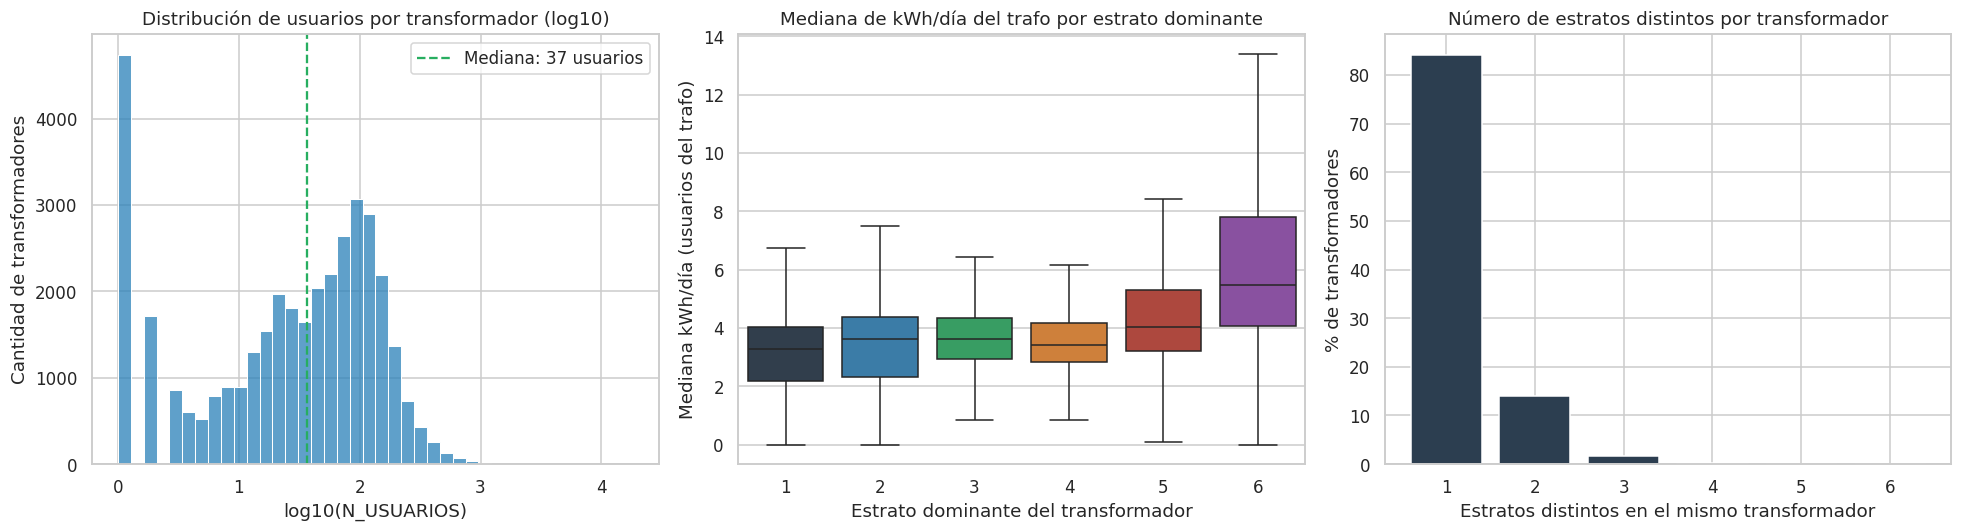

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución de cantidad de usuarios por transformador (escala log10)
sns.histplot(np.log10(df_trafo_estratos['N_USUARIOS']), bins=40, kde=False, color=PALETA[1], ax=axes[0])
axes[0].axvline(np.log10(df_trafo_estratos['N_USUARIOS'].median()), color=PALETA[2], linestyle='--',
                label=f"Mediana: {df_trafo_estratos['N_USUARIOS'].median():.0f} usuarios")
axes[0].set_title('Distribución de usuarios por transformador (log10)')
axes[0].set_xlabel('log10(N_USUARIOS)')
axes[0].set_ylabel('Cantidad de transformadores')
axes[0].legend()

# 2. Consumo diario mediano del transformador según su estrato dominante
sns.boxplot(
    data=df_trafo_estratos,
    x='ESTRATO_DOMINANTE',
    y='KWH_DIA_MEDIANA_USU',
    hue='ESTRATO_DOMINANTE',
    palette=PALETA,
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Mediana de kWh/día del trafo por estrato dominante')
axes[1].set_xlabel('Estrato dominante del transformador')
axes[1].set_ylabel('Mediana kWh/día (usuarios del trafo)')

# 3. Pureza de estrato en los transformadores
conteo_n_est = df_trafo_estratos['N_ESTRATOS_DISTINTOS'].value_counts().sort_index()
axes[2].bar(conteo_n_est.index.astype(str), conteo_n_est.values / len(df_trafo_estratos) * 100, color=PALETA[0])
axes[2].set_title('Número de estratos distintos por transformador')
axes[2].set_xlabel('Estratos distintos en el mismo transformador')
axes[2].set_ylabel('% de transformadores')

plt.tight_layout()
guardar_figura(fig, '01_perfil_transformadores')
plt.show()

## 4. Caracterización de `COD_CIRCUITO_LINEA` (`df_circuitos`) y línea base de tamaño del efecto ($\varepsilon^2$ y $\eta^2$)

En esta sección:
1. Construimos el DataFrame `df_circuitos` para todos los códigos de circuito/línea de `2022–2025` con su cantidad de transformadores, usuarios, consumo diario (media, mediana, $Q_1$, $Q_3$, $\mathrm{IQR}$, `% de ceros`), composición por estrato (`1..6`) y dispersión interna entre sus transformadores.
2. Medimos el **tamaño del efecto real ($\eta^2$ ANOVA y $\varepsilon^2$ de Kruskal-Wallis, tanto brutos como ajustados por grados de libertad)** de `ESTRATO_SECTOR`, `COD_CIRCUITO_LINEA`, `(COD_CIRCUITO_LINEA, ESTRATO_SECTOR)` y `COD_TRANSFORMADOR` sobre el consumo diario medio por usuario (`KWH_DIA_USUARIO_MEDIA`).

In [14]:
# 4.1 Construcción del DataFrame de circuitos (df_circuitos) a partir de usuarios_trafo y df_trafo_estratos
g_circ = usuarios_trafo.groupby('COD_CIRCUITO_LINEA')

df_circuitos_base = g_circ.agg(
    N_TRANSFORMADORES=('COD_TRANSFORMADOR', 'nunique'),
    N_USUARIOS=('NIU_USUARIO', 'count'),
    N_REGISTROS=('N_MESES_USUARIO', 'sum'),
    KWH_DIA_MEDIA_USU=('KWH_DIA_USUARIO_MEDIA', 'mean'),
    KWH_DIA_MEDIANA_USU=('KWH_DIA_USUARIO_MEDIA', 'median'),
    KWH_DIA_STD_USU=('KWH_DIA_USUARIO_MEDIA', 'std'),
    SUMA_KWH_DIA_CIRC=('SUMA_KWH_DIA', 'sum'),
    TOTAL_CEROS=('N_CEROS_USUARIO', 'sum'),
)

# Cuantiles exactos (Q1, Q3, IQR) por circuito
df_circuitos_base['KWH_DIA_Q1_USU'] = g_circ['KWH_DIA_USUARIO_MEDIA'].quantile(0.25)
df_circuitos_base['KWH_DIA_Q3_USU'] = g_circ['KWH_DIA_USUARIO_MEDIA'].quantile(0.75)
df_circuitos_base['KWH_DIA_IQR_USU'] = df_circuitos_base['KWH_DIA_Q3_USU'] - df_circuitos_base['KWH_DIA_Q1_USU']
df_circuitos_base['KWH_DIA_STD_USU'] = df_circuitos_base['KWH_DIA_STD_USU'].fillna(0.0)
df_circuitos_base['KWH_DIA_TOTAL_CIRC'] = df_circuitos_base['KWH_DIA_MEDIA_USU'] * df_circuitos_base['N_USUARIOS']
df_circuitos_base['PCT_CEROS'] = (df_circuitos_base['TOTAL_CEROS'] / df_circuitos_base['N_REGISTROS']) * 100

# Dispersión entre las medianas de los transformadores que pertenecen al mismo circuito
g_trafo_en_circ = df_trafo_estratos.groupby('COD_CIRCUITO_LINEA')['KWH_DIA_MEDIANA_USU']
df_circuitos_base['STD_MEDIANA_TRAFOS'] = g_trafo_en_circ.std().fillna(0.0)
df_circuitos_base['IQR_MEDIANA_TRAFOS'] = g_trafo_en_circ.quantile(0.75) - g_trafo_en_circ.quantile(0.25)

# Composición por estrato (1..6) dentro de cada circuito
conteo_est_circ = (
    usuarios_trafo.groupby(['COD_CIRCUITO_LINEA', 'ESTRATO_SECTOR'])['NIU_USUARIO']
    .count()
    .unstack(fill_value=0)
    .reindex(columns=ESTRATOS, fill_value=0)
)
conteo_est_circ.columns = [f'CANT_ESTRATO_{e}' for e in ESTRATOS]

pct_est_circ = conteo_est_circ.div(conteo_est_circ.sum(axis=1), axis=0) * 100
pct_est_circ.columns = [f'PCT_ESTRATO_{e}' for e in ESTRATOS]

estrato_dom_circ = conteo_est_circ.values.argmax(axis=1) + 1
pureza_circ = pct_est_circ.max(axis=1)
n_estratos_circ = (conteo_est_circ > 0).sum(axis=1)

df_circuitos = (
    df_circuitos_base
    .join(conteo_est_circ)
    .join(pct_est_circ)
    .assign(
        ESTRATO_DOMINANTE=pd.Series(estrato_dom_circ, index=conteo_est_circ.index, dtype='int8'),
        PUREZA_ESTRATO_PCT=pureza_circ,
        N_ESTRATOS_DISTINTOS=n_estratos_circ.astype('int8')
    )
    .sort_values('N_USUARIOS', ascending=False)
)

print(f'df_circuitos: {df_circuitos.shape[0]:,} circuitos x {df_circuitos.shape[1]} columnas')
df_circuitos.head(10)

df_circuitos: 1,097 circuitos x 30 columnas


,N_TRANSFORMADORES,N_USUARIOS,N_REGISTROS,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,SUMA_KWH_DIA_CIRC,TOTAL_CEROS,KWH_DIA_Q1_USU,KWH_DIA_Q3_USU,...,CANT_ESTRATO_6,PCT_ESTRATO_1,PCT_ESTRATO_2,PCT_ESTRATO_3,PCT_ESTRATO_4,PCT_ESTRATO_5,PCT_ESTRATO_6,ESTRATO_DOMINANTE,PUREZA_ESTRATO_PCT,N_ESTRATOS_DISTINTOS
COD_CIRCUITO_LINEA,,,,,,,,,,,,,,,,,,,,,
,16786,522168,21412758,3.7146,3.0654,3.2462,"84,653,921.1612",748302,2.0146,4.5002,...,17694,4.6309,28.5648,38.1176,19.2783,6.0199,3.3886,3,38.1176,6
0550,51,17454,205597,2.2332,0.9000,3.3434,"818,336.9992",8852,0.0667,3.3586,...,279,1.6099,41.1653,26.7961,26.6243,2.2058,1.5985,2,41.1653,6
0302,63,12386,549579,3.1933,2.8518,2.4986,"1,757,976.9013",15905,2.0651,3.7848,...,0,15.5256,84.4663,0.0081,0.0000,0.0000,0.0000,2,84.4663,3
0305,70,11720,549345,3.3234,2.8277,2.5997,"1,809,766.2586",21838,2.0060,3.9236,...,0,2.6792,94.9147,2.4061,0.0000,0.0000,0.0000,2,94.9147,3
1223,86,11709,545087,3.7589,3.2666,2.7954,"2,060,151.2741",21941,2.0716,4.8353,...,10,97.6001,1.9728,0.2306,0.0000,0.1110,0.0854,1,97.6001,5
0111,124,11180,524238,4.6647,3.9801,3.2573,"2,448,187.7240",13638,2.7077,5.7673,...,0,0.0447,70.9571,28.9893,0.0089,0.0000,0.0000,2,70.9571,4
0312,75,10654,506868,3.8518,3.4011,2.7329,"1,946,541.5250",8321,2.4628,4.5383,...,0,0.0188,99.9625,0.0188,0.0000,0.0000,0.0000,2,99.9625,3
0315,82,10555,487452,3.3619,2.8350,2.6606,"1,635,770.4771",16460,1.9588,4.0542,...,0,67.9299,31.9469,0.1232,0.0000,0.0000,0.0000,1,67.9299,3
0313,80,10539,490501,3.8977,3.2693,3.0259,"1,914,049.5671",11472,2.2751,4.6951,...,0,54.0184,45.9152,0.0664,0.0000,0.0000,0.0000,1,54.0184,3


In [15]:
# 4.2 Estadísticos descriptivos de los circuitos
cols_desc_circ = [
    'N_TRANSFORMADORES', 'N_USUARIOS', 'N_REGISTROS',
    'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_STD_USU', 'KWH_DIA_IQR_USU',
    'STD_MEDIANA_TRAFOS', 'IQR_MEDIANA_TRAFOS', 'PCT_CEROS',
    'PUREZA_ESTRATO_PCT', 'N_ESTRATOS_DISTINTOS'
]
df_circuitos[cols_desc_circ].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
N_TRANSFORMADORES,"1,097.0000",50.2944,507.2584,1.0000,1.0000,6.0000,21.0000,51.0000,114.0000,180.2000,"16,786.0000"
N_USUARIOS,"1,097.0000","2,260.3564","15,906.3097",1.0000,2.0000,18.0000,333.0000,"3,094.0000","6,763.6000","10,038.1200","522,168.0000"
N_REGISTROS,"1,097.0000","99,380.8824","653,819.2058",1.0000,12.0000,133.0000,"11,519.0000","139,607.0000","302,253.8000","444,765.4400","21,412,758.0000"
KWH_DIA_MEDIA_USU,"1,097.0000",4.1074,2.8894,0.0000,1.3562,2.7478,3.9584,4.7821,6.6048,14.4398,42.1249
KWH_DIA_MEDIANA_USU,"1,097.0000",3.2904,2.9123,0.0000,0.7169,2.0791,3.2026,3.8652,5.3421,12.2801,42.1249
KWH_DIA_STD_USU,"1,097.0000",3.5235,2.2390,0.0000,0.7536,2.4282,3.3387,4.1957,6.5071,12.9317,24.0222
KWH_DIA_IQR_USU,"1,097.0000",3.0239,2.1830,0.0000,0.5122,2.1086,2.8383,3.4951,5.3653,10.3346,35.4891
STD_MEDIANA_TRAFOS,"1,079.0000",2.2469,2.5999,0.0000,0.0000,0.8408,1.4990,2.7958,6.5761,11.5364,30.0838
IQR_MEDIANA_TRAFOS,"1,079.0000",1.8207,2.1980,0.0000,0.0000,0.8023,1.2976,2.2012,4.8144,9.2729,35.4891
PCT_CEROS,"1,097.0000",6.4024,8.9449,0.0000,0.0000,2.3333,3.6364,7.2000,21.5196,42.8571,100.0000


In [16]:
# 4.3 Cálculo vectorizado de Tamaño del Efecto (Eta^2 ANOVA y Epsilon^2 de Kruskal-Wallis)
y_val = usuarios_trafo['KWH_DIA_USUARIO_MEDIA'].to_numpy(dtype='float64')
y_log = np.log1p(np.clip(y_val, 0.0, None))
y_rank = usuarios_trafo['KWH_DIA_USUARIO_MEDIA'].rank(method='average').to_numpy(dtype='float64')

N_total = len(usuarios_trafo)
ss_tot_val = ((y_val - y_val.mean()) ** 2).sum()
ss_tot_log = ((y_log - y_log.mean()) ** 2).sum()
mean_rank_global = (N_total + 1.0) / 2.0

usuarios_trafo['CIRCUITO_X_ESTRATO'] = (
    usuarios_trafo['COD_CIRCUITO_LINEA'].astype(str) + '_E' + usuarios_trafo['ESTRATO_SECTOR'].astype(str)
)

def evaluar_efecto_agrupador(df_u, col_grupo, nombre_nivel):
    g = df_u.groupby(col_grupo, observed=True)
    n_j = g['KWH_DIA_USUARIO_MEDIA'].count().to_numpy(dtype='float64')
    k = len(n_j)
    
    # Eta^2 sobre KWH_DIA_USUARIO_MEDIA
    mean_j_val = g['KWH_DIA_USUARIO_MEDIA'].mean().to_numpy(dtype='float64')
    ss_btw_val = (n_j * ((mean_j_val - y_val.mean()) ** 2)).sum()
    eta2_val = ss_btw_val / ss_tot_val
    eta2_adj_val = 1.0 - (1.0 - eta2_val) * (N_total - 1.0) / (N_total - k)
    
    # Eta^2 sobre log1p(KWH_DIA_USUARIO_MEDIA)
    mean_j_log = df_u.assign(_ylog=y_log).groupby(col_grupo, observed=True)['_ylog'].mean().to_numpy(dtype='float64')
    ss_btw_log = (n_j * ((mean_j_log - y_log.mean()) ** 2)).sum()
    eta2_log = ss_btw_log / ss_tot_log
    eta2_adj_log = 1.0 - (1.0 - eta2_log) * (N_total - 1.0) / (N_total - k)
    
    # Epsilon^2 de Kruskal-Wallis (no paramétrico sobre rangos)
    mean_j_rank = df_u.assign(_yrank=y_rank).groupby(col_grupo, observed=True)['_yrank'].mean().to_numpy(dtype='float64')
    H_kw = (12.0 / (N_total * (N_total + 1.0))) * (n_j * ((mean_j_rank - mean_rank_global) ** 2)).sum()
    eps2_kw = H_kw / (N_total - 1.0)
    eps2_adj_kw = (H_kw - k + 1.0) / (N_total - k)
    
    return {
        'Nivel / Variable': nombre_nivel,
        'Cardinalidad (k)': k,
        'Eta2_KWH_DIA (%)': eta2_val * 100,
        'Eta2_Adj_KWH_DIA (%)': eta2_adj_val * 100,
        'Eta2_log1p (%)': eta2_log * 100,
        'Eta2_Adj_log1p (%)': eta2_adj_log * 100,
        'Epsilon2_KW (%)': eps2_kw * 100,
        'Epsilon2_Adj_KW (%)': eps2_adj_kw * 100,
    }

resultados_efectos = pd.DataFrame([
    evaluar_efecto_agrupador(usuarios_trafo, 'ESTRATO_SECTOR', '1. ESTRATO_SECTOR'),
    evaluar_efecto_agrupador(usuarios_trafo, 'COD_CIRCUITO_LINEA', '2. COD_CIRCUITO_LINEA'),
    evaluar_efecto_agrupador(usuarios_trafo, 'CIRCUITO_X_ESTRATO', '3. CIRCUITO x ESTRATO'),
    evaluar_efecto_agrupador(usuarios_trafo, 'COD_TRANSFORMADOR', '4. COD_TRANSFORMADOR'),
]).set_index('Nivel / Variable')

resultados_efectos

,Cardinalidad (k),Eta2_KWH_DIA (%),Eta2_Adj_KWH_DIA (%),Eta2_log1p (%),Eta2_Adj_log1p (%),Epsilon2_KW (%),Epsilon2_Adj_KW (%)
Nivel / Variable,,,,,,,
1. ESTRATO_SECTOR,6,2.1522,2.1520,1.9904,1.9902,1.8780,1.8778
2. COD_CIRCUITO_LINEA,1097,4.9503,4.9082,7.2170,7.1760,6.5862,6.5449
3. CIRCUITO x ESTRATO,3220,7.2019,7.0813,10.0672,9.9503,9.2182,9.1002
4. COD_TRANSFORMADOR,37346,17.2371,15.9715,23.4346,22.2638,22.3451,21.1577


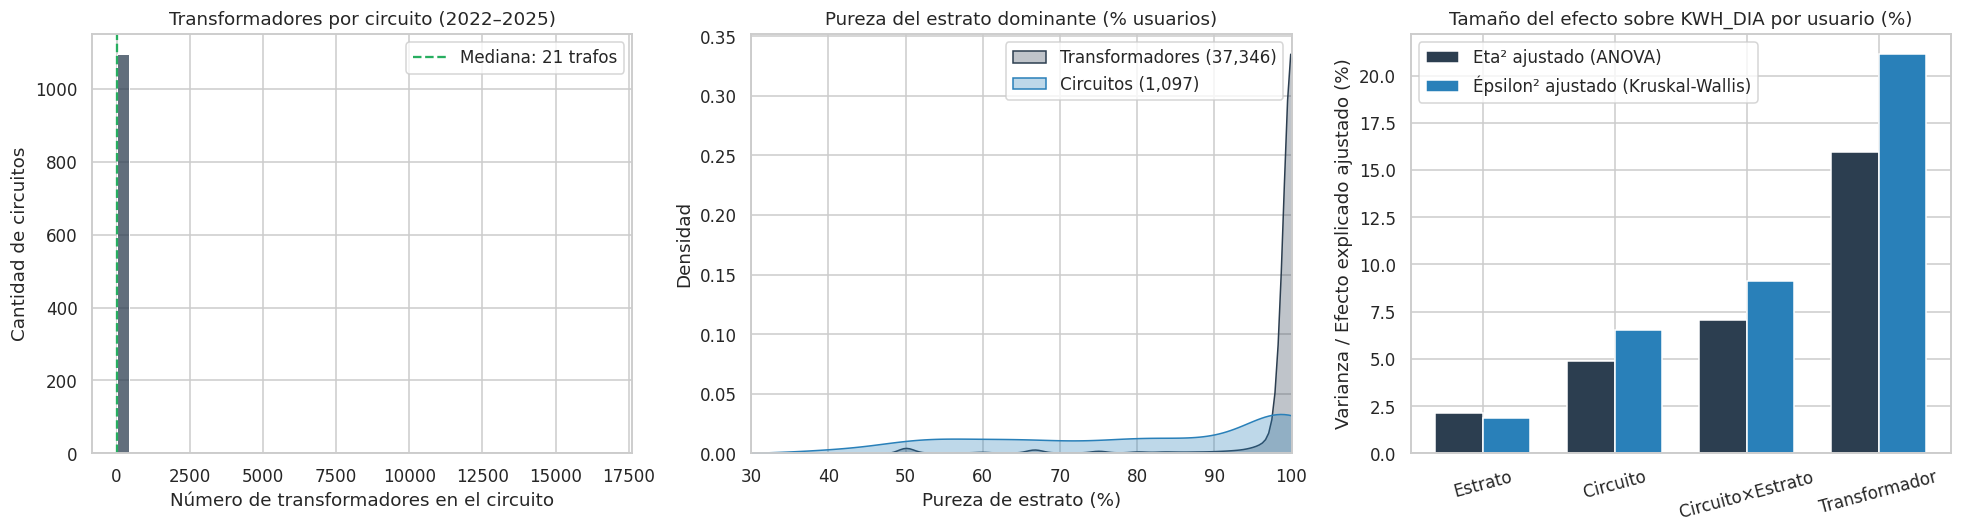

In [17]:
# 4.4 Gráficos diagnósticos de circuitos y escalera de tamaño del efecto
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución de cantidad de transformadores por circuito
sns.histplot(df_circuitos['N_TRANSFORMADORES'], bins=40, kde=False, color=PALETA[0], ax=axes[0])
axes[0].axvline(df_circuitos['N_TRANSFORMADORES'].median(), color=PALETA[2], linestyle='--',
                label=f"Mediana: {df_circuitos['N_TRANSFORMADORES'].median():.0f} trafos")
axes[0].set_title('Transformadores por circuito (2022–2025)')
axes[0].set_xlabel('Número de transformadores en el circuito')
axes[0].set_ylabel('Cantidad de circuitos')
axes[0].legend()

# 2. Pureza de estrato: Circuitos vs Transformadores
sns.kdeplot(df_trafo_estratos['PUREZA_ESTRATO_PCT'], label=f'Transformadores ({len(df_trafo_estratos):,})', color=PALETA[0], fill=True, alpha=0.3, ax=axes[1])
sns.kdeplot(df_circuitos['PUREZA_ESTRATO_PCT'], label=f'Circuitos ({len(df_circuitos):,})', color=PALETA[1], fill=True, alpha=0.3, ax=axes[1])
axes[1].set_title('Pureza del estrato dominante (% usuarios)')
axes[1].set_xlabel('Pureza de estrato (%)')
axes[1].set_ylabel('Densidad')
axes[1].set_xlim(30, 100)
axes[1].legend()

# 3. Comparación de tamaño del efecto ajustado (Eta2_Adj y Epsilon2_Adj)
x_pos = np.arange(len(resultados_efectos))
width = 0.36
axes[2].bar(x_pos - width/2, resultados_efectos['Eta2_Adj_KWH_DIA (%)'], width, label='Eta² ajustado (ANOVA)', color=PALETA[0])
axes[2].bar(x_pos + width/2, resultados_efectos['Epsilon2_Adj_KW (%)'], width, label='Épsilon² ajustado (Kruskal-Wallis)', color=PALETA[1])
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(['Estrato', 'Circuito', 'Circuito×Estrato', 'Transformador'], rotation=15)
axes[2].set_title('Tamaño del efecto sobre KWH_DIA por usuario (%)')
axes[2].set_ylabel('Varianza / Efecto explicado ajustado (%)')
axes[2].legend()

plt.tight_layout()
guardar_figura(fig, '02_perfil_circuitos_y_efectos')
plt.show()

## 5. Clustering independiente de todos los `COD_CIRCUITO_LINEA` y `COD_TRANSFORMADOR` (2022–2025)

Entrenamos **dos modelos de agrupamiento independientes** sobre la totalidad de los circuitos y transformadores del panel 2022–2025:
1. **Preprocesamiento y suavizamiento empírico (*Empirical Bayes Shrinkage*) independiente:**
   - Se recodifica explícitamente el código de circuito vacío `""` como `'SIN_CIRCUITO'` para no mezclar los transformadores sin código de circuito como si fueran un único circuito físico.
   - Para estabilizar las unidades con pocos usuarios ($N < m$), se aplica suavizamiento empírico hacia la mediana de su `ESTRATO_DOMINANTE` de manera independiente en circuitos ($m=30$) y en transformadores ($m=15$):
     $$\tilde{x}_i = w_i x_i + (1 - w_i) \mu_{\text{estrato}}, \quad w_i = \frac{N_i}{N_i + m}$$
2. **Clustering 1 — `CLUSTER_CIRCUITO` (sobre `df_circuitos`):** agrupa los circuitos físicos según su escala ($\log_{10}(\text{N\_TRANSFORMADORES})$, $\log_{10}(\text{N\_USUARIOS})$), consumo mediano e $\mathrm{IQR}$ suavizados, dispersión entre sus transformadores (`IQR_MEDIANA_TRAFOS`), `% de ceros`, `ESTRATO_DOMINANTE` y `PUREZA_ESTRATO_PCT`.
3. **Clustering 2 — `CLUSTER_TRANSFORMADOR` (sobre `df_trafo_estratos`):** agrupa todos los transformadores usando únicamente variables propias del transformador ($\log_{10}(\text{N\_USUARIOS})$, consumo mediano suavizado, $\mathrm{IQR}$ suavizado, `% de ceros` y `ESTRATO_DOMINANTE`).

In [18]:
# 5.1 Limpieza del código vacío en COD_CIRCUITO_LINEA y suavizamiento empírico independiente
usuarios_trafo['COD_CIRCUITO_CLEAN'] = (
    usuarios_trafo['COD_CIRCUITO_LINEA'].astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})
)
df_trafo_estratos['COD_CIRCUITO_CLEAN'] = (
    df_trafo_estratos['COD_CIRCUITO_LINEA'].astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})
)
df_circuitos.index = df_circuitos.index.astype(str).str.strip()
df_circuitos = df_circuitos.rename(index={'': 'SIN_CIRCUITO'})

# Priors por ESTRATO_DOMINANTE para suavizar unidades con pocos usuarios (sin cruzar circuito con transformador)
prior_trafo_mediana = df_trafo_estratos.groupby('ESTRATO_DOMINANTE')['KWH_DIA_MEDIANA_USU'].median()
prior_trafo_iqr = df_trafo_estratos.groupby('ESTRATO_DOMINANTE')['KWH_DIA_IQR_USU'].median()

prior_circ_mediana = df_circuitos.groupby('ESTRATO_DOMINANTE')['KWH_DIA_MEDIANA_USU'].median()
prior_circ_iqr = df_circuitos.groupby('ESTRATO_DOMINANTE')['KWH_DIA_IQR_USU'].median()

# Suavizamiento para Transformadores (m = 15 usuarios)
M_TRAFO = 15.0
w_trafo = df_trafo_estratos['N_USUARIOS'] / (df_trafo_estratos['N_USUARIOS'] + M_TRAFO)
df_trafo_estratos['KWH_DIA_MEDIANA_SMOOTH'] = (
    w_trafo * df_trafo_estratos['KWH_DIA_MEDIANA_USU']
    + (1.0 - w_trafo) * df_trafo_estratos['ESTRATO_DOMINANTE'].map(prior_trafo_mediana)
)
df_trafo_estratos['KWH_DIA_IQR_SMOOTH'] = (
    w_trafo * df_trafo_estratos['KWH_DIA_IQR_USU']
    + (1.0 - w_trafo) * df_trafo_estratos['ESTRATO_DOMINANTE'].map(prior_trafo_iqr)
)
df_trafo_estratos['LOG_N_USUARIOS'] = np.log10(1.0 + df_trafo_estratos['N_USUARIOS'])

# Suavizamiento para Circuitos (m = 30 usuarios)
M_CIRC = 30.0
w_circ = df_circuitos['N_USUARIOS'] / (df_circuitos['N_USUARIOS'] + M_CIRC)
df_circuitos['KWH_DIA_MEDIANA_SMOOTH'] = (
    w_circ * df_circuitos['KWH_DIA_MEDIANA_USU']
    + (1.0 - w_circ) * df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_mediana)
)
df_circuitos['KWH_DIA_IQR_SMOOTH'] = (
    w_circ * df_circuitos['KWH_DIA_IQR_USU']
    + (1.0 - w_circ) * df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_iqr)
)
df_circuitos['LOG_N_TRANSFORMADORES'] = np.log10(1.0 + df_circuitos['N_TRANSFORMADORES'])
df_circuitos['LOG_N_USUARIOS'] = np.log10(1.0 + df_circuitos['N_USUARIOS'])
df_circuitos['IQR_MEDIANA_TRAFOS'] = df_circuitos['IQR_MEDIANA_TRAFOS'].fillna(0.0)

print('Variables preparadas correctamente para ambos clusterings independientes.')

Variables preparadas correctamente para ambos clusterings independientes.


In [19]:
# 5.2 Evaluación de K para el Clustering de COD_CIRCUITO_LINEA (independiente)
features_circ = [
    'LOG_N_TRANSFORMADORES', 'LOG_N_USUARIOS',
    'KWH_DIA_MEDIANA_SMOOTH', 'KWH_DIA_IQR_SMOOTH',
    'IQR_MEDIANA_TRAFOS', 'PCT_CEROS',
    'ESTRATO_DOMINANTE', 'PUREZA_ESTRATO_PCT'
]

df_circ_validos = df_circuitos.loc[df_circuitos.index != 'SIN_CIRCUITO'].copy()
scaler_circ = RobustScaler()
X_circ = scaler_circ.fit_transform(df_circ_validos[features_circ])

eta2_ref_circ = resultados_efectos.loc['2. COD_CIRCUITO_LINEA', 'Eta2_Adj_KWH_DIA (%)']
eps2_ref_circ = resultados_efectos.loc['2. COD_CIRCUITO_LINEA', 'Epsilon2_Adj_KW (%)']

K_GRID_CIRC = [4, 5, 6, 8, 10, 12, 15, 20]
metricas_k_circ = []
modelos_circ = {}

for k in K_GRID_CIRC:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    labels = km.fit_predict(X_circ)
    modelos_circ[k] = labels
    
    sil = silhouette_score(X_circ, labels)
    ch = calinski_harabasz_score(X_circ, labels)
    
    mapa_c = pd.Series(labels, index=df_circ_validos.index).to_dict()
    mapa_c['SIN_CIRCUITO'] = -1
    usuarios_trafo['_tmp_cl_circ'] = usuarios_trafo['COD_CIRCUITO_CLEAN'].map(mapa_c).fillna(-1).astype('int16')
    
    ef = evaluar_efecto_agrupador(usuarios_trafo, '_tmp_cl_circ', f'K={k}')
    metricas_k_circ.append({
        'K_Circuitos': k,
        'Inercia': km.inertia_,
        'Silueta': sil,
        'Calinski_Harabasz': ch,
        'Eta2_Adj_KWH_DIA (%)': ef['Eta2_Adj_KWH_DIA (%)'],
        'Retencion_Eta2 (%)': (ef['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_circ) * 100,
        'Epsilon2_Adj_KW (%)': ef['Epsilon2_Adj_KW (%)'],
        'Retencion_Epsilon2 (%)': (ef['Epsilon2_Adj_KW (%)'] / eps2_ref_circ) * 100,
    })

usuarios_trafo.drop(columns=['_tmp_cl_circ'], inplace=True)
df_eval_k_circ = pd.DataFrame(metricas_k_circ).set_index('K_Circuitos')
df_eval_k_circ

,Inercia,Silueta,Calinski_Harabasz,Eta2_Adj_KWH_DIA (%),Retencion_Eta2 (%),Epsilon2_Adj_KW (%),Retencion_Epsilon2 (%)
K_Circuitos,,,,,,,
4,"6,387.8775",0.2111,268.6673,1.6790,34.2083,2.7482,41.9902
5,"5,355.6748",0.2841,292.6860,1.8027,36.7279,2.2935,35.0422
6,"4,746.2332",0.2341,291.9622,2.0725,42.2240,3.0110,46.0051
8,"3,937.0692",0.2201,282.8885,3.0404,61.9446,4.1455,63.3399
10,"3,331.7640",0.2372,281.4422,3.3184,67.6094,4.3632,66.6654
12,"2,976.2468",0.2300,269.0738,3.4196,69.6697,4.3903,67.0807
15,"2,597.8607",0.2016,252.7845,3.4839,70.9802,4.3815,66.9456
20,"2,146.9712",0.2113,236.2304,3.6893,75.1657,4.6063,70.3804


In [20]:
# Asignación de CLUSTER_CIRCUITO (K = 8 clústeres físicos + C00 para SIN_CIRCUITO) ordenados de menor a mayor consumo
K_OPT_CIRC = 8
df_circ_validos['_raw_cluster'] = modelos_circ[K_OPT_CIRC]

orden_c = (
    df_circ_validos.groupby('_raw_cluster')['KWH_DIA_MEDIANA_USU']
    .median()
    .sort_values()
    .index
)
mapa_orden_c = {old_lbl: f'C{i+1:02d}' for i, old_lbl in enumerate(orden_c)}
df_circ_validos['CLUSTER_CIRCUITO'] = df_circ_validos['_raw_cluster'].map(mapa_orden_c)

df_circuitos['CLUSTER_CIRCUITO'] = df_circ_validos['CLUSTER_CIRCUITO']
if 'SIN_CIRCUITO' in df_circuitos.index:
    df_circuitos.loc['SIN_CIRCUITO', 'CLUSTER_CIRCUITO'] = 'C00_SIN_CIRC'

# Propagar CLUSTER_CIRCUITO a usuarios_trafo
usuarios_trafo['CLUSTER_CIRCUITO'] = usuarios_trafo['COD_CIRCUITO_CLEAN'].map(df_circuitos['CLUSTER_CIRCUITO'])

resumen_clusters_circuito = (
    df_circuitos.groupby('CLUSTER_CIRCUITO')
    .agg(
        N_CIRCUITOS=('N_USUARIOS', 'count'),
        TOTAL_TRANSFORMADORES=('N_TRANSFORMADORES', 'sum'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_TRAFOS_CIRC=('N_TRANSFORMADORES', 'median'),
        MEDIANA_USU_CIRC=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA=('KWH_DIA_MEDIANA_USU', 'median'),
        IQR_KWH_DIA=('KWH_DIA_IQR_USU', 'median'),
        MEDIANA_PCT_CEROS=('PCT_CEROS', 'median'),
        ESTRATO_MODA=('ESTRATO_DOMINANTE', lambda s: int(s.mode().iloc[0])),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean')
    )
)
resumen_clusters_circuito

,N_CIRCUITOS,TOTAL_TRANSFORMADORES,TOTAL_USUARIOS,MEDIANA_TRAFOS_CIRC,MEDIANA_USU_CIRC,MEDIANA_KWH_DIA,IQR_KWH_DIA,MEDIANA_PCT_CEROS,ESTRATO_MODA,PUREZA_MEDIA_PCT
CLUSTER_CIRCUITO,,,,,,,,,,
C00_SIN_CIRC,1,16786,522168,"16,786.0000","522,168.0000",3.0654,2.4857,3.4947,3,38.1176
C01,6,11,95,1.5000,1.5000,0.2285,0.0000,85.9628,2,91.6667
C02,98,1084,14021,7.0000,21.5000,1.2438,2.2149,20.0545,2,77.6042
C03,298,4806,120994,10.0000,21.0000,2.0506,2.3965,4.9709,2,74.5826
C04,73,1474,20684,11.0000,31.0000,3.1040,4.5714,7.0972,2,74.3040
C05,296,13285,770242,35.0000,"2,035.0000",3.2820,2.3163,3.2070,3,82.0611
C06,254,12536,937380,47.0000,"3,469.0000",3.8590,3.4244,2.6626,3,87.2995
C07,65,5172,93471,62.0000,"1,218.0000",4.9406,4.2032,3.4678,6,81.0517
C08,6,19,556,2.5000,4.5000,11.5167,16.4765,2.4272,2,76.3485


In [21]:
# 5.3 Evaluación de K para el Clustering de COD_TRANSFORMADOR (todos los transformadores, 100 % independiente del circuito)
features_trafo = [
    'LOG_N_USUARIOS',
    'KWH_DIA_MEDIANA_SMOOTH',
    'KWH_DIA_IQR_SMOOTH',
    'PCT_CEROS',
    'ESTRATO_DOMINANTE'
]

scaler_trafo = RobustScaler()
X_trafo = scaler_trafo.fit_transform(df_trafo_estratos[features_trafo])

eta2_ref_trafo = resultados_efectos.loc['4. COD_TRANSFORMADOR', 'Eta2_Adj_KWH_DIA (%)']
eps2_ref_trafo = resultados_efectos.loc['4. COD_TRANSFORMADOR', 'Epsilon2_Adj_KW (%)']

K_GRID_TRAFO = [6, 8, 10, 12, 15, 20, 25, 30]
metricas_k_trafo = []
modelos_trafo = {}

for k in K_GRID_TRAFO:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    labels = km.fit_predict(X_trafo)
    modelos_trafo[k] = labels
    
    sil = silhouette_score(X_trafo, labels, sample_size=10000, random_state=SEMILLA)
    ch = calinski_harabasz_score(X_trafo, labels)
    
    mapa_t = pd.Series(labels, index=df_trafo_estratos.index)
    usuarios_trafo['_tmp_cl_trafo'] = usuarios_trafo['COD_TRANSFORMADOR'].map(mapa_t).astype('int16')
    
    ef = evaluar_efecto_agrupador(usuarios_trafo, '_tmp_cl_trafo', f'K={k}')
    metricas_k_trafo.append({
        'K_Transformadores': k,
        'Inercia': km.inertia_,
        'Silueta_Muestra10k': sil,
        'Calinski_Harabasz': ch,
        'Eta2_Adj_KWH_DIA (%)': ef['Eta2_Adj_KWH_DIA (%)'],
        'Retencion_Eta2 (%)': (ef['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_trafo) * 100,
        'Epsilon2_Adj_KW (%)': ef['Epsilon2_Adj_KW (%)'],
        'Retencion_Epsilon2 (%)': (ef['Epsilon2_Adj_KW (%)'] / eps2_ref_trafo) * 100,
    })

usuarios_trafo.drop(columns=['_tmp_cl_trafo'], inplace=True)
df_eval_k_trafo = pd.DataFrame(metricas_k_trafo).set_index('K_Transformadores')
df_eval_k_trafo

,Inercia,Silueta_Muestra10k,Calinski_Harabasz,Eta2_Adj_KWH_DIA (%),Retencion_Eta2 (%),Epsilon2_Adj_KW (%),Retencion_Epsilon2 (%)
K_Transformadores,,,,,,,
6,"77,025.3333",0.2704,"28,989.5162",10.3515,64.8124,14.2765,67.4766
8,"58,878.6879",0.3147,"28,731.1801",10.0973,63.2204,13.8030,65.2386
10,"48,811.8291",0.3196,"27,809.3633",10.8624,68.0111,14.0796,66.5460
12,"42,635.1143",0.2929,"26,539.7572",12.1582,76.1242,15.6103,73.7811
15,"36,741.7475",0.2798,"24,623.2562",12.7078,79.5650,16.4622,77.8075
20,"31,391.5968",0.2611,"21,567.6350",13.4525,84.2282,17.9005,84.6054
25,"27,957.2256",0.2516,"19,360.2810",13.6407,85.4066,18.0993,85.5452
30,"25,197.8357",0.2238,"17,915.7083",13.8340,86.6165,18.4342,87.1279


In [22]:
# Asignación de CLUSTER_TRANSFORMADOR (K = 12) ordenados de menor a mayor consumo mediano
K_OPT_TRAFO = 12
df_trafo_estratos['_raw_cluster'] = modelos_trafo[K_OPT_TRAFO]

orden_t = (
    df_trafo_estratos.groupby('_raw_cluster')['KWH_DIA_MEDIANA_USU']
    .median()
    .sort_values()
    .index
)
mapa_orden_t = {old_lbl: f'T{i+1:02d}' for i, old_lbl in enumerate(orden_t)}
df_trafo_estratos['CLUSTER_TRANSFORMADOR'] = df_trafo_estratos['_raw_cluster'].map(mapa_orden_t)
df_trafo_estratos.drop(columns=['_raw_cluster'], inplace=True)

# Propagar CLUSTER_TRANSFORMADOR a df_trafo_consumo y usuarios_trafo
df_trafo_consumo['CLUSTER_TRANSFORMADOR'] = df_trafo_estratos['CLUSTER_TRANSFORMADOR']
usuarios_trafo['CLUSTER_TRANSFORMADOR'] = usuarios_trafo['COD_TRANSFORMADOR'].map(df_trafo_estratos['CLUSTER_TRANSFORMADOR'])

resumen_clusters_trafo = (
    df_trafo_estratos.groupby('CLUSTER_TRANSFORMADOR')
    .agg(
        N_TRANSFORMADORES=('N_USUARIOS', 'count'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_USU_TRAFO=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA=('KWH_DIA_MEDIANA_USU', 'median'),
        MEDIA_KWH_DIA=('KWH_DIA_MEDIA_USU', 'mean'),
        MEDIANA_IQR_KWH_DIA=('KWH_DIA_IQR_USU', 'median'),
        MEDIANA_PCT_CEROS=('PCT_CEROS', 'median'),
        ESTRATO_MODA=('ESTRATO_DOMINANTE', lambda s: int(s.mode().iloc[0])),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean')
    )
)
resumen_clusters_trafo['PCT_TRANSFORMADORES'] = resumen_clusters_trafo['N_TRANSFORMADORES'] / len(df_trafo_estratos) * 100
resumen_clusters_trafo['PCT_USUARIOS'] = resumen_clusters_trafo['TOTAL_USUARIOS'] / resumen_clusters_trafo['TOTAL_USUARIOS'].sum() * 100
resumen_clusters_trafo

,N_TRANSFORMADORES,TOTAL_USUARIOS,MEDIANA_USU_TRAFO,MEDIANA_KWH_DIA,MEDIA_KWH_DIA,MEDIANA_IQR_KWH_DIA,MEDIANA_PCT_CEROS,ESTRATO_MODA,PUREZA_MEDIA_PCT,PCT_TRANSFORMADORES,PCT_USUARIOS
CLUSTER_TRANSFORMADOR,,,,,,,,,,,
T01,197,641,1.0000,0.0167,0.5384,0.0000,87.5000,2,98.6125,0.5275,0.0259
T02,389,2973,1.0000,0.1906,1.5529,0.0000,52.1739,2,96.7588,1.0416,0.1199
T03,578,17139,3.0000,0.8275,2.1549,0.8366,33.3333,2,94.4185,1.5477,0.6912
T04,1192,53495,6.0000,1.7826,2.9103,1.7534,18.2548,2,93.0878,3.1918,2.1574
T05,6221,15920,1.0000,2.8560,3.9597,0.0000,0.0000,2,96.4730,16.6577,0.6420
T06,2976,173494,23.5000,2.9435,3.5906,2.3419,8.4283,3,95.3477,7.9687,6.9968
T07,7280,916102,89.0000,3.0168,3.3696,1.7195,2.8477,3,98.6766,19.4934,36.9454
T08,4508,173089,25.0000,3.9739,4.9504,2.3611,2.2099,5,99.2573,12.0709,6.9805
T09,6817,707450,96.0000,3.9949,4.7083,3.1419,1.9887,2,98.5947,18.2536,28.5307


In [23]:
# 5.4 Comparación global de Tamaño del Efecto: Categorías originales vs. Clústeres independientes y combinados
usuarios_trafo['CLUSTER_CIRC_X_TRAFO'] = (
    usuarios_trafo['CLUSTER_CIRCUITO'].astype(str) + '_' + usuarios_trafo['CLUSTER_TRANSFORMADOR'].astype(str)
)

comparacion_final_efectos = pd.DataFrame([
    evaluar_efecto_agrupador(usuarios_trafo, 'ESTRATO_SECTOR', '1. ESTRATO_SECTOR (6)'),
    evaluar_efecto_agrupador(usuarios_trafo, 'CLUSTER_CIRCUITO', f'2. CLUSTER_CIRCUITO ({K_OPT_CIRC}+1)'),
    evaluar_efecto_agrupador(usuarios_trafo, 'COD_CIRCUITO_CLEAN', f'3. COD_CIRCUITO_LINEA original ({len(df_circuitos):,})'),
    evaluar_efecto_agrupador(usuarios_trafo, 'CLUSTER_TRANSFORMADOR', f'4. CLUSTER_TRANSFORMADOR ({K_OPT_TRAFO})'),
    evaluar_efecto_agrupador(usuarios_trafo, 'CLUSTER_CIRC_X_TRAFO', '5. CLUSTER_CIRCUITO x CLUSTER_TRAFO'),
    evaluar_efecto_agrupador(usuarios_trafo, 'COD_TRANSFORMADOR', f'6. COD_TRANSFORMADOR original ({len(df_trafo_estratos):,})'),
]).set_index('Nivel / Variable')

# Cálculo de V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR
tabla_contingencia = pd.crosstab(usuarios_trafo['CLUSTER_CIRCUITO'], usuarios_trafo['CLUSTER_TRANSFORMADOR'])
obs = tabla_contingencia.to_numpy(dtype='float64')
n_tot_c = obs.sum()
esperados = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n_tot_c
chi2_val = (((obs - esperados) ** 2) / esperados).sum()
min_dim = min(obs.shape[0] - 1, obs.shape[1] - 1)
cramers_v = np.sqrt(chi2_val / (n_tot_c * min_dim))
print(f'V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR: {cramers_v:.4f} (asociación moderada -> aportan información complementaria)')

comparacion_final_efectos

V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR: 0.3316 (asociación moderada -> aportan información complementaria)


,Cardinalidad (k),Eta2_KWH_DIA (%),Eta2_Adj_KWH_DIA (%),Eta2_log1p (%),Eta2_Adj_log1p (%),Epsilon2_KW (%),Epsilon2_Adj_KW (%)
Nivel / Variable,,,,,,,
1. ESTRATO_SECTOR (6),6,2.1522,2.1520,1.9904,1.9902,1.8780,1.8778
2. CLUSTER_CIRCUITO (8+1),9,3.0407,3.0404,4.5010,4.5007,4.1458,4.1455
"3. COD_CIRCUITO_LINEA original (1,097)",1097,4.9503,4.9082,7.2170,7.1760,6.5862,6.5449
4. CLUSTER_TRANSFORMADOR (12),12,12.1586,12.1582,16.3701,16.3697,15.6107,15.6103
5. CLUSTER_CIRCUITO x CLUSTER_TRAFO,94,12.5172,12.5139,17.2591,17.2560,16.2262,16.2230
"6. COD_TRANSFORMADOR original (37,346)",37346,17.2371,15.9715,23.4346,22.2638,22.3451,21.1577


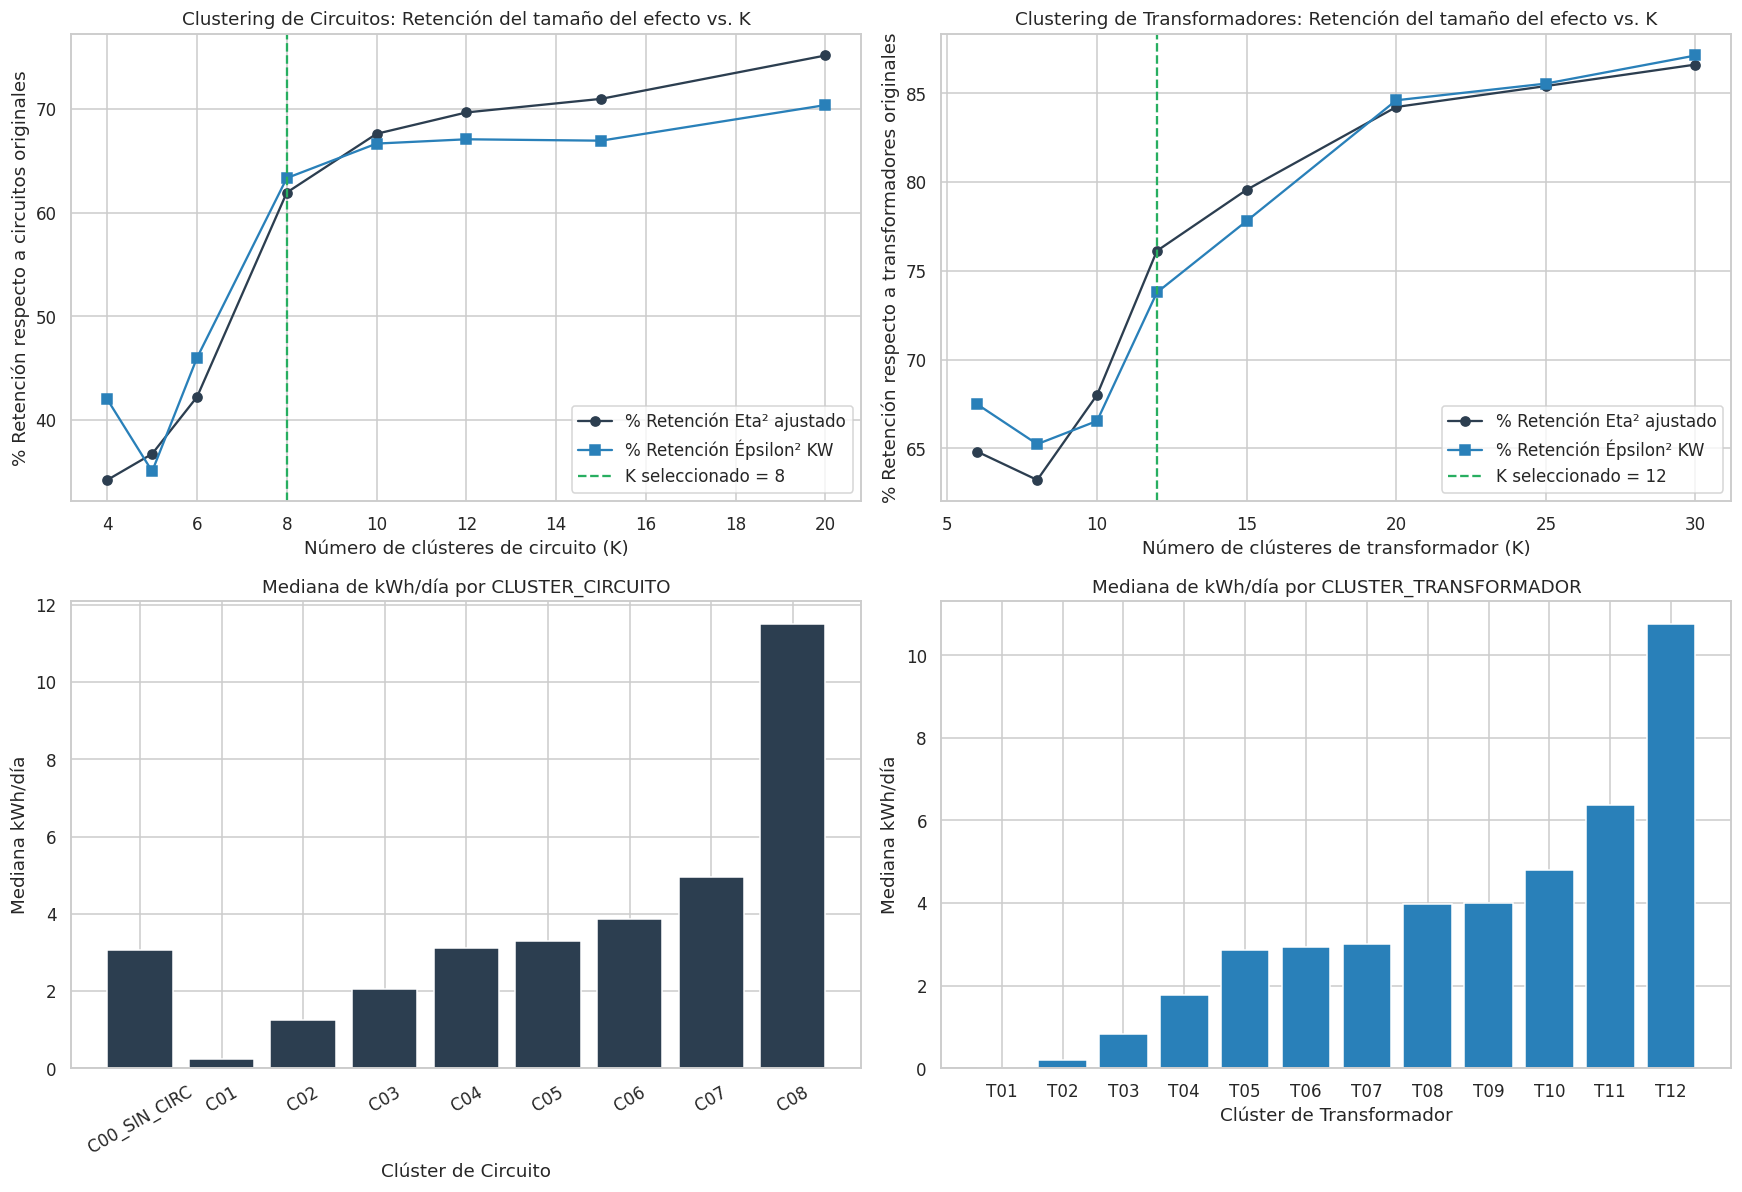

In [24]:
# Visualización de curvas de selección de K y perfiles de los clústeres
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Curva de retención de efecto para Circuitos
ax1 = axes[0, 0]
ax1.plot(df_eval_k_circ.index, df_eval_k_circ['Retencion_Eta2 (%)'], marker='o', color=PALETA[0], label='% Retención Eta² ajustado')
ax1.plot(df_eval_k_circ.index, df_eval_k_circ['Retencion_Epsilon2 (%)'], marker='s', color=PALETA[1], label='% Retención Épsilon² KW')
ax1.axvline(K_OPT_CIRC, color=PALETA[2], linestyle='--', label=f'K seleccionado = {K_OPT_CIRC}')
ax1.set_title('Clustering de Circuitos: Retención del tamaño del efecto vs. K')
ax1.set_xlabel('Número de clústeres de circuito (K)')
ax1.set_ylabel('% Retención respecto a circuitos originales')
ax1.legend(loc='lower right')

# 2. Curva de retención de efecto para Transformadores
ax2 = axes[0, 1]
ax2.plot(df_eval_k_trafo.index, df_eval_k_trafo['Retencion_Eta2 (%)'], marker='o', color=PALETA[0], label='% Retención Eta² ajustado')
ax2.plot(df_eval_k_trafo.index, df_eval_k_trafo['Retencion_Epsilon2 (%)'], marker='s', color=PALETA[1], label='% Retención Épsilon² KW')
ax2.axvline(K_OPT_TRAFO, color=PALETA[2], linestyle='--', label=f'K seleccionado = {K_OPT_TRAFO}')
ax2.set_title('Clustering de Transformadores: Retención del tamaño del efecto vs. K')
ax2.set_xlabel('Número de clústeres de transformador (K)')
ax2.set_ylabel('% Retención respecto a transformadores originales')
ax2.legend(loc='lower right')

# 3. Perfil de consumo mediano por CLUSTER_CIRCUITO
ax3 = axes[1, 0]
ax3.bar(resumen_clusters_circuito.index, resumen_clusters_circuito['MEDIANA_KWH_DIA'], color=PALETA[0])
ax3.set_title('Mediana de kWh/día por CLUSTER_CIRCUITO')
ax3.set_xlabel('Clúster de Circuito')
ax3.set_ylabel('Mediana kWh/día')
ax3.tick_params(axis='x', rotation=30)

# 4. Perfil de consumo mediano por CLUSTER_TRANSFORMADOR
ax4 = axes[1, 1]
ax4.bar(resumen_clusters_trafo.index, resumen_clusters_trafo['MEDIANA_KWH_DIA'], color=PALETA[1])
ax4.set_title('Mediana de kWh/día por CLUSTER_TRANSFORMADOR')
ax4.set_xlabel('Clúster de Transformador')
ax4.set_ylabel('Mediana kWh/día')

plt.tight_layout()
guardar_figura(fig, '03_clustering_circuitos_y_transformadores')
plt.show()

## 6. Exportación de los catálogos de clústeres y DataFrames de perfil a Google Drive
Se guardan los diccionarios/tablas de mapeo (`COD_TRANSFORMADOR` $\to$ `CLUSTER_TRANSFORMADOR` y `COD_CIRCUITO_LINEA` $\to$ `CLUSTER_CIRCUITO`) junto con los DataFrames completos de caracterización en `/content/drive/MyDrive/Superintendencia/Catalogos_Categorias` para integrarlos directamente en el modelado predictivo.

In [25]:
os.makedirs(DIR_CATALOGOS, exist_ok=True)

# 1. Catálogo ligero de mapeo de Transformadores
catalogo_trafo = (
    df_trafo_estratos[[
        'CLUSTER_TRANSFORMADOR', 'ESTRATO_DOMINANTE', 'PUREZA_ESTRATO_PCT',
        'N_USUARIOS', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_IQR_USU', 'PCT_CEROS'
    ]]
    .reset_index()
)
ruta_cat_trafo = os.path.join(DIR_CATALOGOS, 'catalogo_clusters_transformador.parquet')
catalogo_trafo.to_parquet(ruta_cat_trafo, index=False)

# 2. Catálogo ligero de mapeo de Circuitos (incluyendo mapeo para cadena vacía "")
catalogo_circuito = (
    df_circuitos[[
        'CLUSTER_CIRCUITO', 'ESTRATO_DOMINANTE', 'PUREZA_ESTRATO_PCT',
        'N_TRANSFORMADORES', 'N_USUARIOS', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_IQR_USU', 'PCT_CEROS'
    ]]
    .reset_index()
    .rename(columns={'index': 'COD_CIRCUITO_LINEA'})
)
# Asegurar que el código original '' también esté mapeado directamente
if 'SIN_CIRCUITO' in df_circuitos.index:
    fila_vacia = catalogo_circuito.loc[catalogo_circuito['COD_CIRCUITO_LINEA'] == 'SIN_CIRCUITO'].copy()
    fila_vacia['COD_CIRCUITO_LINEA'] = ''
    catalogo_circuito = pd.concat([catalogo_circuito, fila_vacia], ignore_index=True)

ruta_cat_circ = os.path.join(DIR_CATALOGOS, 'catalogo_clusters_circuito.parquet')
catalogo_circuito.to_parquet(ruta_cat_circ, index=False)

# 3. Guardar los 3 DataFrames analíticos completos
df_trafo_consumo.reset_index().to_parquet(os.path.join(DIR_CATALOGOS, 'df_trafo_consumo.parquet'), index=False)
df_trafo_estratos.reset_index().to_parquet(os.path.join(DIR_CATALOGOS, 'df_trafo_estratos.parquet'), index=False)
df_circuitos.reset_index().rename(columns={'index': 'COD_CIRCUITO_LINEA'}).to_parquet(
    os.path.join(DIR_CATALOGOS, 'df_circuitos.parquet'), index=False
)

print('Catálogos y DataFrames exportados exitosamente en:', DIR_CATALOGOS)
for nombre_arch in sorted(os.listdir(DIR_CATALOGOS)):
    tam_mb = os.path.getsize(os.path.join(DIR_CATALOGOS, nombre_arch)) / (1024 ** 2)
    print(f' - {nombre_arch}: {tam_mb:.2f} MB')

Catálogos y DataFrames exportados exitosamente en: /content/drive/MyDrive/Superintendencia/Catalogos_Categorias
 - catalogo_clusters_circuito.parquet: 0.05 MB
 - catalogo_clusters_transformador.parquet: 1.23 MB
 - df_circuitos.parquet: 0.22 MB
 - df_trafo_consumo.parquet: 3.56 MB
 - df_trafo_estratos.parquet: 3.38 MB
